# Titanic: Exploratory Data Analysis + a Simple Survival Model

This notebook:
1. Loads the classic Titanic passenger dataset
2. Explores it (missing data, survival rates by sex / class / age)
3. Engineers a couple of simple features
4. Trains and compares two classifiers (Logistic Regression, Random Forest) to predict survival
5. Evaluates them on a held-out test set

Runs end to end with no API keys and no local files — the dataset is pulled from a public URL.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Load the data

In [2]:
DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(DATA_URL)
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


## 2. Exploratory data analysis

In [4]:
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
missing_pct = (missing / len(df) * 100).round(1)
pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})

,missing_count,missing_pct
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


Overall survival rate: 38.4%


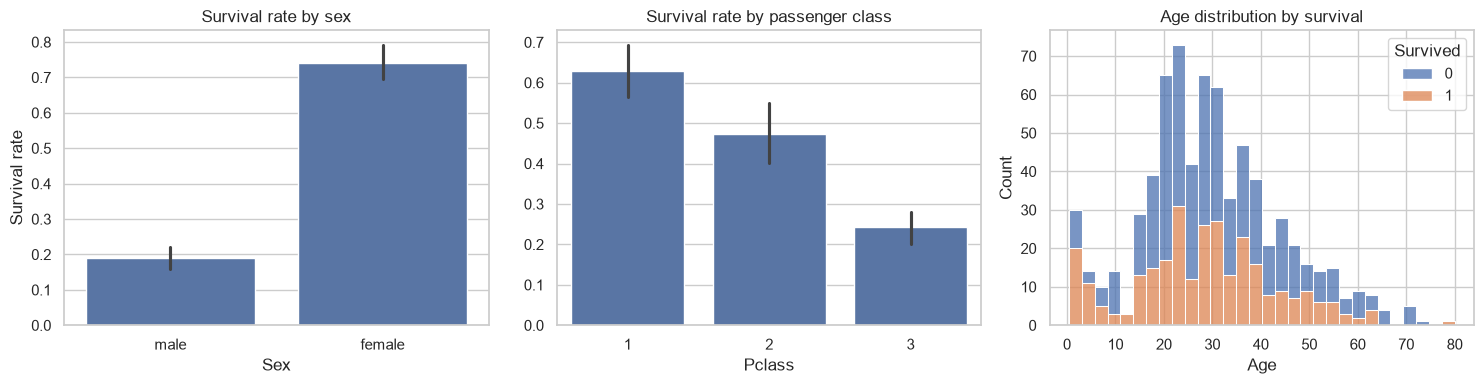

In [5]:
overall_rate = df["Survived"].mean()
print(f"Overall survival rate: {overall_rate:.1%}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(data=df, x="Sex", y="Survived", ax=axes[0])
axes[0].set_title("Survival rate by sex")
axes[0].set_ylabel("Survival rate")

sns.barplot(data=df, x="Pclass", y="Survived", ax=axes[1])
axes[1].set_title("Survival rate by passenger class")
axes[1].set_ylabel("")

sns.histplot(data=df, x="Age", hue="Survived", multiple="stack", bins=30, ax=axes[2])
axes[2].set_title("Age distribution by survival")

plt.tight_layout()
plt.show()

Two patterns jump out immediately: women survived at a far higher rate than men, and survival
rate drops sharply as passenger class goes from 1st to 3rd. Both make sense historically — "women
and children first" boarding, and 1st-class cabins being closer to the lifeboat deck.

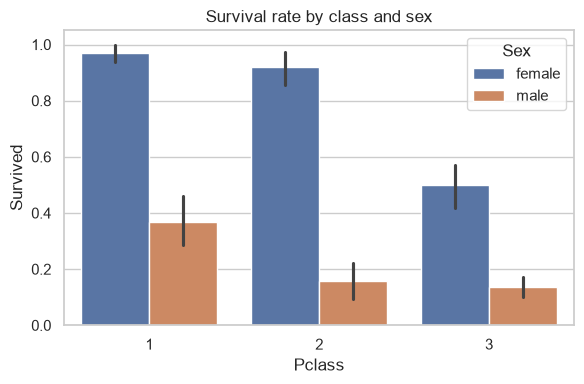

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=df, x="Pclass", y="Survived", hue="Sex", ax=ax)
ax.set_title("Survival rate by class and sex")
plt.tight_layout()
plt.show()

## 3. Feature engineering

A couple of simple, interpretable features derived from the raw columns:
- `FamilySize` = siblings/spouses + parents/children aboard + the passenger themself
- `IsAlone` = traveling with no family aboard

In [7]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

FEATURES = ["Pclass", "Sex", "Age", "Fare", "FamilySize", "IsAlone", "Embarked"]
NUMERIC_FEATURES = ["Pclass", "Age", "Fare", "FamilySize", "IsAlone"]
CATEGORICAL_FEATURES = ["Sex", "Embarked"]

X = df[FEATURES]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {len(X_train)} rows, Test: {len(X_test)} rows")

Train: 712 rows, Test: 179 rows


## 4. Build and train models

Both models share the same preprocessing: median-impute + scale numeric columns, most-frequent
impute + one-hot encode categorical columns. `Age` and `Embarked` both have missing values (see
the missing-data table above), so imputation is required, not optional.

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]),
            NUMERIC_FEATURES,
        ),
        (
            "categorical",
            Pipeline(
                [
                    ("impute", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            CATEGORICAL_FEATURES,
        ),
    ]
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42),
}

results = {}
for name, model in models.items():
    pipeline = Pipeline([("preprocess", preprocessor), ("model", model)])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = {"pipeline": pipeline, "accuracy": acc, "y_pred": y_pred}
    print(f"{name}: accuracy = {acc:.3f}")

Logistic Regression: accuracy = 0.793


Random Forest: accuracy = 0.810


## 5. Evaluate the better model

In [9]:
best_name = max(results, key=lambda n: results[n]["accuracy"])
best = results[best_name]
print(f"Best model: {best_name} (accuracy = {best['accuracy']:.3f})\n")
print(classification_report(y_test, best["y_pred"], target_names=["Did not survive", "Survived"]))

Best model: Random Forest (accuracy = 0.810)

                 precision    recall  f1-score   support

Did not survive       0.79      0.95      0.86       110
       Survived       0.87      0.59      0.71        69

       accuracy                           0.81       179
      macro avg       0.83      0.77      0.78       179
   weighted avg       0.82      0.81      0.80       179



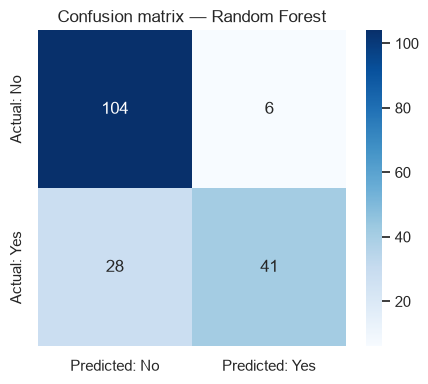

In [10]:
cm = confusion_matrix(y_test, best["y_pred"])
fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted: No", "Predicted: Yes"],
    yticklabels=["Actual: No", "Actual: Yes"],
    ax=ax,
)
ax.set_title(f"Confusion matrix — {best_name}")
plt.tight_layout()
plt.show()

## Conclusion

Sex and passenger class are by far the strongest signals for survival in this dataset — a model
using only a handful of simple features reaches a reasonable accuracy without any heavy feature
engineering. This notebook is meant as a clear, minimal EDA → model → evaluate template rather
than a state-of-the-art Titanic solution; a natural next step would be tuning hyperparameters
with cross-validation, or engineering a title feature from the `Name` column (e.g. "Mr"/"Mrs"/
"Master").